# 1 Molecular dynamics

## Describing the motion of a single particle

<div style="background-color: #f0f8ff; border: 2px solid #4682b4; padding: 10px;">
<strong>Note:</strong> This notebook contains the code for sections 1.1-1.2 from the book  

**Simulation of Complex Systems**  
Aykut Argun, Agnese Callegari, and Giovanni Volpe<br>
IOP Publishing, Bristol, UK, 2021<br>
ISBN: 978-0-7503-3843-1<br>
[https://iopscience.iop.org/book/mono/978-0-7503-3843-1](https://iopscience.iop.org/book/mono/978-0-7503-3843-1)

You can find the other notebooks on the [Simulation of Complex Systems GitHub page](../../)
</div>

Matter can be described by interacting particles obeying Newton’s laws. 

**Key advantages:**

* Molecular dynamics can be made complex at will.
* There are codes for simulating millions of particles.
* Often done in parallel computing / with supercomputers.


**Historical reading:** L. Verlet (1967), “Computer experiments on classical fluids. I”, *Physical Review* **159**, 98, [https://doi.org/10.1103/PhysRev.159.98](https://doi.org/10.1103/PhysRev.159.98). 

**Application example:** 
L. Casalino, et al. (2021), "AI-driven multiscale simulations illuminate mechanisms of SARS-CoV-2 spike dynamics", *The International Journal of High Performance Computing Applications* **35**, 432-451 [https://doi.org/10.1177/10943420211006452](https://doi.org/10.1177/10943420211006452).

## 1.1 Single particle 


For a particle of mass $m$, Newton's second law states: 
$\quad F = ma \quad $. 

This is equivalent to
$\quad \displaystyle \frac{{\rm d}{x}}{{\rm d}t} = v(t) \quad $
and
$\quad \displaystyle \frac{{\rm d}{v}}{{\rm d}t} = \frac{F}{m} \quad $

with initial conditions $\quad x(0) = x_0 \quad $ and $\quad v(0) = v_0 \quad $

(textbook Eqs. 1.1–1.3). 


The computer advances by *discrete* steps $\Delta t$. 

### Euler algorithm 

Explicit Euler is a finite difference integration scheme using values at the *beginning* of each step (Eq. 1.5).

### Test case: The Harmonic Oscillator 

We test how well the Euler algorithm performs against a very well-known case, the harmonic oscillator, where the exact analytical solution is known.

The force is:
$$F=-kx \quad \quad \mbox{(Hooke's law)}$$


(textbook Exercise 1.1)

In [4]:
import numpy as np
import matplotlib.pyplot as plt

<a id="harmonic-oscillator"></a> We define the parameters of the harmonic oscillator:

In [5]:
# parameters
m = 0.1  # [kg] mass
k = 5.0  # [N/m] elastic constant

# initial conditions
x0 = 0.1  # [m] initial position
v0 = 0.0  # [m/s] initial velocity

# discretization
dt = 0.002  # [s] time step, delta t

print(f'--- Parameters of the Harmonic Oscillator ---')
print(f'')
print(f'            mass: m = {m:.3f} kg')
print(f'elastic constant: k = {k:.3f} N/m')
print(f'initial position: x0 = {x0:.3f} m')
print(f'initial velocity: v0 = {v0:.3f} m/s')

--- Parameters of the Harmonic Oscillator ---

            mass: m = 0.100 kg
elastic constant: k = 5.000 N/m
initial position: x0 = 0.100 m
initial velocity: v0 = 0.000 m/s


From the parameters, we calculate the relevant physical quantities:

In [18]:
# physical quantities 

# angular frequency
omega = np.sqrt(k / m)  
print(f' omega = {omega:.6f} rad/s')

# period 
period = 2 * np.pi / omega 
print(f' period = {period:.6f} s')

# amplitude 
A = np.sqrt(x0 ** 2 + (v0 / omega) ** 2)  
print(f' A = {A:.6f} m')

# phase
phi = np.arctan2((-v0 / A / omega), x0 / A)  
print(f' phi = {phi:.6f} rad')

# initial energy (also total energy, by energy conservation)
initial_energy = ( 
    0.5 * m * v0 ** 2 + 0.5 * k * x0 ** 2
)  
print(f' initial_energy = {initial_energy:.6f} J')

 omega = 7.071068 rad/s
 period = 0.888577 s
 A = 0.100000 m
 phi = -0.000000 rad
 initial_energy = 0.025000 J


Let's check the time step against the period:

In [7]:
# test how dt compares respect to the period
ratio = dt / period
print(f'\n ratio (dt / period) = {ratio:.6f}')
if ratio > 0.1:
    print('\t dt is too large: decrease it to have ratio <= 0.1')
else:
    print('\t dt is sufficiently small')


 ratio (dt / period) = 0.002251
	 dt is sufficiently small


<div style="background-color:#f0f8ff; border: 2px solid #4682b4; padding: 10px;">
     
**Note:** The harmonic oscillator describes the case of a perfect oscillation, without losses due to friction. The total mechanical energy (that is the sum of the potential energy stored in the spring and kinetic energy of the oscillating mass) is constant in time. The oscillation goes on forever.
    
</div>

We generate the exact solution over a given time interval:

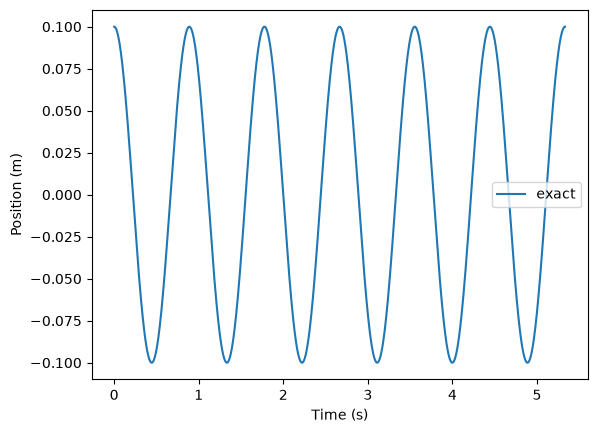

In [19]:
# generate exact solution over a given time interval

n_osc = 6  # number of complete oscillations 

time = np.arange(0, n_osc * period + dt / 2, dt)  # time interval

x_exact = A * np.cos(omega * time + phi)
v_exact = -omega * A * np.sin(omega * time + phi) 


# plot exact solution

plt.plot(time, x_exact, label="exact")
plt.xlabel("Time (s)"); 
plt.ylabel("Position (m)"); 
plt.legend(); 
plt.show()

We plot the total energy:

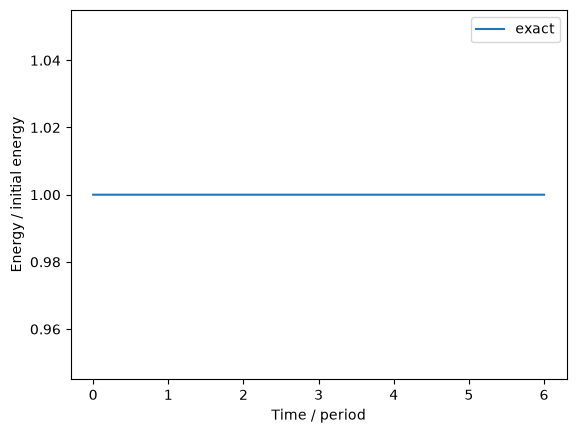

In [9]:
# compare kinetic, potential, and total energy

KE_exact = 0.5 * m * np.array(v_exact)**2 
PE_exact = 0.5 * k * np.array(x_exact)**2
TE_exact = KE_exact + PE_exact

plt.plot(time / period, TE_exact / initial_energy, label="exact")
plt.xlabel("Time / period"); 
plt.ylabel("Energy / initial energy"); 
plt.legend(); 
plt.show()

### Euler algorithm and the harmonic oscillator (Exercise 1.1)

We record every state and update position and velocity using *old* values. 

<a id="euler-method"></a>

In [10]:
# generate Euler's method solution over the given time interval

x = x0
v = v0

x_euler = [x] 
v_euler = [v]

for t in time[1:]:
    force = -k * x
    x_next = x + v * dt
    v_next = v + force / m * dt
    x = x_next
    v = v_next
    x_euler.append(x)
    v_euler.append(v)

We compare the trajectory with the exact solution

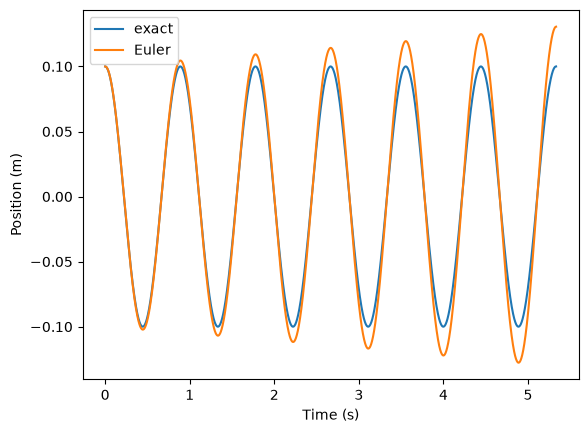

In [11]:
# plot Euler's method solution vs exact solution

# position
plt.plot(time, x_exact, label="exact")
plt.plot(time, x_euler, label="Euler")
plt.xlabel("Time (s)"); 
plt.ylabel("Position (m)"); 
plt.legend(); 
plt.show(); 


We compare the total energy to the exact solution.

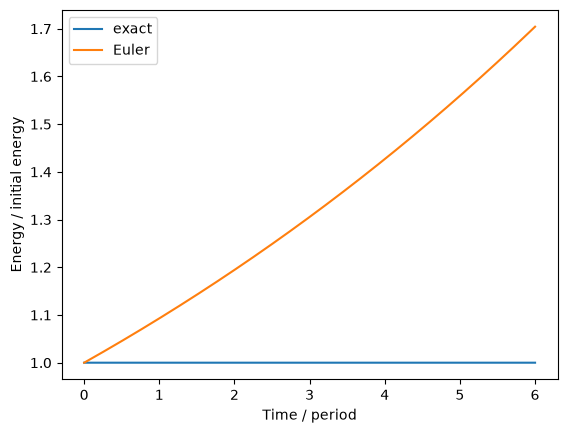

In [12]:
# compare kinetic, potential, and total energy (Euler vs exact)

KE_euler = 0.5 * m * np.array(v_euler)**2 
PE_euler = 0.5 * k * np.array(x_euler)**2
TE_euler = KE_euler + PE_euler

plt.plot(time / period, TE_exact / initial_energy, label="exact")
plt.plot(time / period, TE_euler / initial_energy, label="Euler")
plt.xlabel("Time / period"); 
plt.ylabel("Energy / initial energy"); 
plt.legend(); 
plt.show()

<a id="leapfrog-method"></a>

### Leapfrog: evaluate the force at the midpoint

The book's drift–kick–drift leapfrog algorithm (Eq. 1.8) first moves the position half a step, updates the velocity using the midpoint force, and completes the position step. For position-dependent forces, this symmetric integrator avoids Euler's systematic oscillator energy growth.


In [13]:
# generate leapfrog method solution over the given time interval

x = x0
v = v0

x_leap = [x] 
v_leap = [v]

for t in time[1:]:
    midpoint = x + 0.5 * dt * v
    force_mid = -k * midpoint
    v = v + dt * force_mid / m
    x = midpoint + 0.5 * dt * v
    x_leap.append(x) 
    v_leap.append(v)

Let's compare the leapfrog solution to the exact solution.

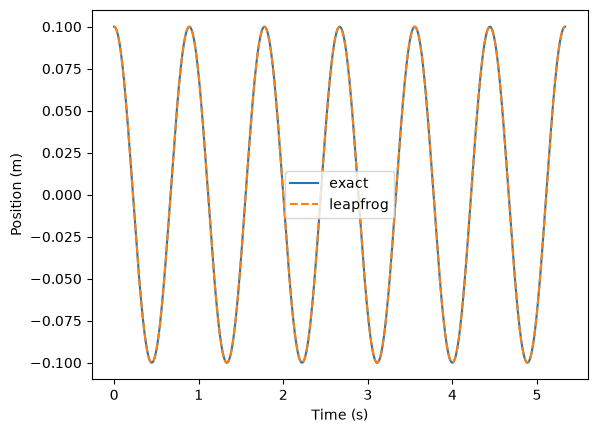

In [14]:
# plot leapfrog method solution vs exact solution

# position
plt.plot(time, x_exact, label="exact")
plt.plot(time, x_leap, "--", label="leapfrog")
plt.xlabel("Time (s)"); 
plt.ylabel("Position (m)"); 
plt.legend(); 
plt.show(); 


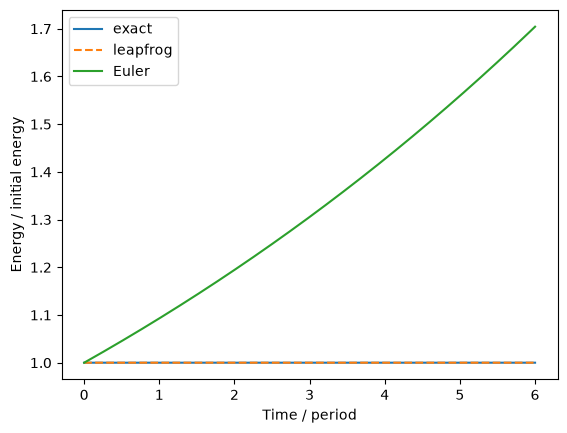

In [15]:
# compare kinetic, potential, and total energy (numerical vs exact)

KE_leap = 0.5 * m * np.array(v_leap)**2 
PE_leap = 0.5 * k * np.array(x_leap)**2
TE_leap = KE_leap + PE_leap

plt.plot(
    time / period, 
    TE_exact / initial_energy, 
    label="exact"
)
plt.plot(
    time / period, 
    TE_leap / initial_energy, 
    "--",
    label="leapfrog"
)
plt.plot(
    time / period, 
    TE_euler / initial_energy, 
    label="Euler"
)
plt.xlabel("Time / period"); 
plt.ylabel("Energy / initial energy"); 
plt.legend(); 
plt.show()

**Think:** In the leapfrog method, is the total energy conserved? How can you check this?

<a id="time-reversibility"></a>

## 1.2 Time reversibility

Reverse the velocity after $N$ steps and propagate for another $N$ steps (Exercise 1.4). For a conservative force, the ideal motion retraces the original path. Floating-point roundoff and finite timesteps can still cause errors.

In [16]:
x = x_leap[-1]
v = -v_leap[-1]

backward_x = [x]
backward_v = [v]

for step in range(len(time) - 1):
    midpoint = x + 0.5 * dt * v
    v = v - dt * k * midpoint / m
    x = midpoint + 0.5 * dt * v
    backward_x.append(x)
    backward_v.append(v)

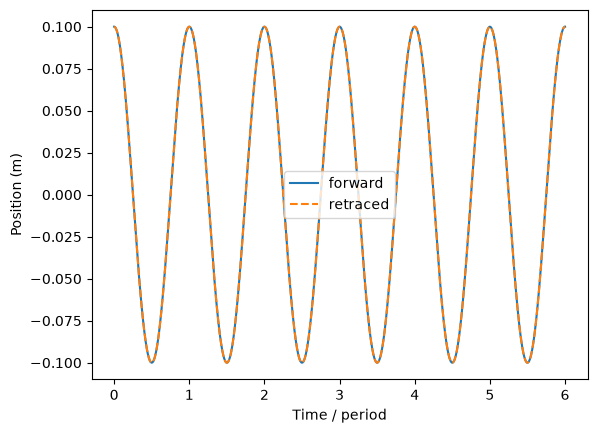

Return-position error (m): 4.3021142204224816e-16


In [17]:
# plot backwards-retraced path

plt.plot(
    time / period, 
    x_leap, 
    label="forward"
)
plt.plot(
    time / period, 
    backward_x[::-1], 
    "--", 
    label="retraced"
)
plt.xlabel("Time / period"); 
plt.ylabel("Position (m)"); 
plt.legend(); 
plt.show()

print("Return-position error (m):", abs(x - x0))

<a id="questions"></a>

## Questions

Here you find the questions:
    
* [Q1: generalities on 1d harmonic oscillator](#q1)
    
* [Q2: generalization to a 2d harmonic oscillator](#q2)
    
* [Q3: Euler method](#q3)
    
* [Q4: leapfrog method](#q4)
    
* [Q5: time reversibility](#q5)
    
* [Q6: Exercise 1.6: damped harmonic oscillator](#q6)


<a id="q1"></a>**Question 1:** Generalities on 1d harmonic oscillator.

Refer to the [harmonic oscillator](#harmonic-oscillator)

[Go back to questions](#questions)

a. Why should $dt$ be sufficiently small? 

b. What happens if $dt > T / 2$ ?

c. What do the following quantities represent? $A$ (A), $\omega$ (omega), $T$ (period), $\phi$ (phi)

d. Which of the quantities characterizing the harmonic oscillator ($A$ (A), $\omega$ (omega), $T$ (period), $\phi$ (phi)) are *independent* of the initial conditions?

e. I am given $A$ (A), $\omega$ (omega) and $\phi$ (phi). How do I find: $x(0)$ (x0)? $v(0)$ (v0)? $T$ (period)? $m$ (m)? $k$ (k)?
   
f. How does the velocity $v(t)$ vary with time for the exact solution?

g. Plot the kinetic energy of the harmonic oscillator.

h. How does the kinetic energy vary with time?

i. Plot the potential energy of the harmonic oscillator.

j. How does the potential energy vary with time?


<a id="q2"></a>**Question 2:** Generalization to a 2d harmonic oscillator.

Refer to the [harmonic oscillator](#harmonic-oscillator)

[Go back to questions](#questions)

a. Write the exact solution for each component $x(t)$ and $y(t)$. Note that you have two distinct elastic constants ($k_x$ and $k_y$), the initial position is $\mathbf{r}_0 = x_0 \hat{\mathbf{x}} +  y_0 \hat{\mathbf{y}}$, and the initial velocity is $\mathbf{v}_0 = v_{x0} \hat{\mathbf{x}} +  v_{y0} \hat{\mathbf{y}}$.
    
b. Calculate the period and the angular frequency of each component. Is the period in $x$ the same as the period in $y$? What about the angular frequency?
   
c. Calculate the amplitude in each component. Are the two amplitudes the same in $x$ and $y$?
    
d. Write the expression of the velocity in each component, as a function of time. 
    
e. Write the expression of the kinetic, potential, total energy in each component, as a function of time.  
    
f. Write the expression of the kinetic, potential, total energy summing up for all components, as a function of time. 
    
g. Plot $x(t)$ and $y(t)$ versus time over a time interval that includes at least three oscillation both in x and in y. 
    
h. Assume $k_{y} = \frac{1}{2} k_{x}$. Plot the solution you have found in the $xy$ plane. Do you expect it to be periodic in the $xy$ plane? 


<a id="q3"></a>**Question 3:** Euler method.

Refer to the [Euler method](#euler-method)

[Go back to questions](#questions)

a. We modify the Euler's code (inside the for cycle, lines 10-16) in the following way:
```python
    force = -k * x 
    x = x + v * dt 
    v = v + force / m * dt 
    x_euler.append(x) 
    v_euler.append(v) 
```
Is the implementation equivalent to the Euler's scheme? Why or why not?
    
    
b. We modify the Euler's code (inside the for cycle, lines 10-16) in the following way:
```python
    force = -k * x 
    v = v + force / m * dt 
    x = x + v * dt 
    v_euler.append(v) 
    x_euler.append(x) 
```
Is the implementation equivalent to the Euler's scheme? Why or why not?
    
    
c. We modify the Euler's code (inside the for cycle, lines 10-16) in the following way:
```python
    x = x + v * dt 
    v = v + (-k * x) / m * dt 
    x_euler.append(x) 
    v_euler.append(v) 
```
Is the implementation equivalent to the Euler's scheme? Why or why not?

    
d. We modify the Euler's code (inside the for cycle, lines 10-16) in the following way:
```python
    x, v = x + v * dt, v + (-k * x) / m * dt,     
    x_euler.append(x), v_euler.append(v)
```
For each of the modifications above: is the implementation equivalent to the Euler's scheme? Why or why not?


e. How does the velocity vary with time for the Euler method?


f. Is the Euler solution a good solution for the harmonic oscillator? Why or why not?


g. Does making the time step smaller necessarily prevent long-term energy drift of Euler scheme?


h. We modify the integration scheme as follows: first we obtain the new velocity as in the Euler scheme, then we use the new velocity to calculate the new position. Is this integration scheme equivalent to Euler's? 


<a id="q4"></a>**Question 4:** Leapfrog method. 

Refer to the [leapfrog method](#leapfrog-method)

[Go back to questions](#questions)

a. Use Taylor expansions to establish its order.


b. We modify the leapfrog code in the following way:
```python
    v_mid = v + 0.5 * dt * (-k * x) / m
    x = x + dt * v_mid
    v = v_mid + 0.5 * dt * (-k * x) / m
    x_leap.append(x) 
    v_leap.append(v)
```
Is the implementation equivalent to the leapfrog scheme? Why or why not?
    
    
c. We modify the leapfrog code in the following way:
```python
    x = x + 0.5 * dt * v
    v = v + dt * (-k * x) / m
    x = x + 0.5 * dt * v    
    x_leap.append(x) 
    v_leap.append(v)
```
Is the implementation equivalent to the leapfrog scheme? Why or why not?
    
    
d. We modify the leapfrog code in the following way:
```python
    v = v + 0.5 * dt * (-k * x) / m
    x = x + dt * v
    v = v + 0.5 * dt * (-k * x) / m
    x_leap.append(x) 
    v_leap.append(v)
```
Is the implementation equivalent to the leapfrog scheme? Why or why not?
    
    
e. We modify the leapfrog code in the following way:
```python
    v_mid = v + 0.5 * dt * (-k * x) / m
    x = x + dt * v
    v = v_mid + 0.5 * dt * (-k * x) / m
    x_leap.append(x) 
    v_leap.append(v)
```    
Is the implementation equivalent to the leapfrog scheme? Why or why not?


f. How does the velocity vary with time for the leapfrog method?


g. Is the leapfrog solution a *good* solution for the harmonic oscillator? Why or why not?


h. Is there an exact energy conservation for the leapfrog method? Why or why not?



<a id="q5"></a>**Question 5:** Time reversibility.

Refer to [time reversibility](#time-reversibility)

[Go back to questions](#questions)

a. Is Euler algorithm time reversible? Implement the code for Euler algorithm. Describe the graph you would obtain for the position.


<a id="q6"></a>**Question 6:** Exercise 1.5: the damped harmonic oscillator. 

Refer to [harmonic oscillator](#harmonic-orcillator), [Euler method](#euler-method), [leapfrog method](#leapfrog-method)

[Go back to questions](#questions)

a. Study the exact solution of the damped harmonic oscillator (force: $F=-kx-bv$) in the case of light damping (i.e., $b < 2 \sqrt{mk}$, i.e., in the oscillatory regime) with initial conditions $x_0$ and $v_0$.


b. If $m = 0.6\, \mathrm{kg}$ and $k = 15\, \mathrm{N/m}$, what is a maximum value for $b$ expressed in $\mathrm{N s/m}$ ?
 
 
c. Take $m = 0.6\, \mathrm{kg}$ and $k = 15\, \mathrm{N/m}$, $b = 1\ \mathrm{N s/m}$. Is this value acceptable to have an oscillatory regime?


In the following, we will assume $m = 6\, \mathrm{kg}$ and $k = 1.5\, \mathrm{N/m}$, $b = 1.2\ \mathrm{N s/m}$,


d. Is $dt = 0.1\ \mathrm{s}$ appropriate to describe the system correctly?


e. With an appropriate choice of $dt$, plot the exact solution (position, total energy) with respect to time.
    
    
f. With the same chosen $dt$, find the numerical solution given by the Euler method. Plot the numerical solution found (position, total energy) with respect to time.
    
    
g. With the same chosen $dt$, find the numerical solution given by the leapfrog method. Plot the numerical solution found (position, total energy) with respect to time.

    
h. Is the total energy (kinetic + potential) conserved in a damped oscillator? Explain.

Eulers är sämre på att bevara energi jämfört med leapfrog